# Auditoría reproducible sin datos

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

La fuente Slagdump está documentada, pero falta el archivo ERT crudo; conteos upstream son solo metadatos.

## Método

Una interpretación ERT defendible requiere bytes con derechos, geometría y arreglo, QC/reciprocidad, malla topográfica, modelo de error, ajustes, residuos, datos retenidos y sensibilidad. Una sección suave no demuestra respaldo. Este cuaderno audita cuatro etapas: fuente documentada, bytes presentes, contrato de proceso y resultado reproducible; confirma ausencia local en vez de sustituir silenciosamente el ejemplo upstream. La figura compara tamaño de celda documentado en m; topología y número de celdas aún dependen de la geometría ausente. Conclusión: existe pipeline, pero este resultado de campo no se reproduce desde este checkout. Una ejecución futura parte de bytes adquiridos con derechos y conserva su hash.

El factor geométrico convierte resistencia bajo hipótesis de semiespacio; no es resistividad verdadera a cierta profundidad. Muchas celdas afectan cada dato, con sensibilidad extensa y resolución dependiente de profundidad. Log protege positividad pero cambia el significado de suavidad. El refinamiento se juzga por predicciones estables con ajuste comparable, no por tamaño de celda solo.

## Estado del arte

El estado del arte no es una tabla de posiciones: separe formulación publicada, implementación del producto y evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path
ledger=json.loads((root/"data/source-ledger.json").read_text(encoding="utf-8")); print("ledger mentions Slagdump:","slagdump" in json.dumps(ledger).lower()); raw=list((root/"data").rglob("*.ohm")); print("local .ohm files:",raw,"; inversion from field arrays possible:",bool(raw))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

paraDX [0.3, 0.45] dimensionless; maximum cell size [10.0, 15.0] m; alternate/default ratios 1.5 1.5


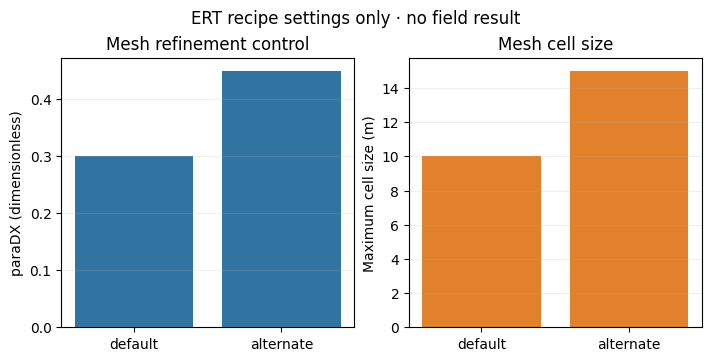

In [2]:
# Read default and alternate mesh parameters from the source AST; no mesh or field model is generated.
import ast
import numpy as np
import matplotlib.pyplot as plt
tree=ast.parse((root/"data-pipeline/ert.py").read_text(encoding="utf-8")); assigns={n.targets[0].id:n.value for n in tree.body if isinstance(n,ast.Assign) and isinstance(n.targets[0],ast.Name)}
default=ast.literal_eval(assigns["INVERSE_OPTIONS"]); alt_node=assigns["ALTERNATE_MESH_OPTIONS"]; overrides={k:ast.literal_eval(v) for k,v in zip([k.value for k in alt_node.keys if k is not None],[v for v in alt_node.values if not isinstance(v,ast.Name)])}; alternate={**default,**overrides}
labels=["default","alternate"]; dx=[default["paraDX"],alternate["paraDX"]]; cell=[default["paraMaxCellSize"],alternate["paraMaxCellSize"]]; print("paraDX",dx,"dimensionless; maximum cell size",cell,"m; alternate/default ratios",cell[1]/cell[0],dx[1]/dx[0])
fig,ax=plt.subplots(1,2,figsize=(7,3.5),constrained_layout=True); x=np.arange(2); ax[0].bar(x,dx,color="#3274a1"); ax[0].set(xticks=x,xticklabels=labels,ylabel="paraDX (dimensionless)",title="Mesh refinement control"); ax[1].bar(x,cell,color="#e1812c"); ax[1].set(xticks=x,xticklabels=labels,ylabel="Maximum cell size (m)",title="Mesh cell size"); [a.grid(axis="y",alpha=.2) for a in ax]; fig.suptitle("ERT recipe settings only · no field result"); plt.show()

### Experimento: proxy de sensibilidad linealizada y compromiso de regularización

El problema DC real es `∇·(σ∇u)=-Iδ`; una inversión de campo defendible requiere el solver numérico directo, electrodos/topografía levantados y modelo de errores. Aquí faltan los bytes fuente. Por eso este experimento usa un **proxy didáctico explícito**, no el solver PDE del producto: las filas de `G` son núcleos amplios que decaen con la profundidad para distintos espaciamientos. Inspeccione valores singulares y resuelva `min ||Gm-d||² + λ||m||²` para una perturbación sintética de log-resistividad, dejando espaciamientos alternados para validación. El barrido muestra cómo λ cambia el ajuste y la recuperación bajo sensibilidad limitada. No valida el caso de campo, la corrección topográfica ni el solver del producto.

Matriz proxy didáctica (18, 30) rango 13 condición 2.72e+13
lambda=0.0001; RMSE ajuste=0.004086; RMSE retenido=0.008446; error relativo del modelo=0.634
lambda=0.01; RMSE ajuste=0.00848; RMSE retenido=0.02045; error relativo del modelo=0.724
lambda=1; RMSE ajuste=0.08764; RMSE retenido=0.08576; error relativo del modelo=0.830


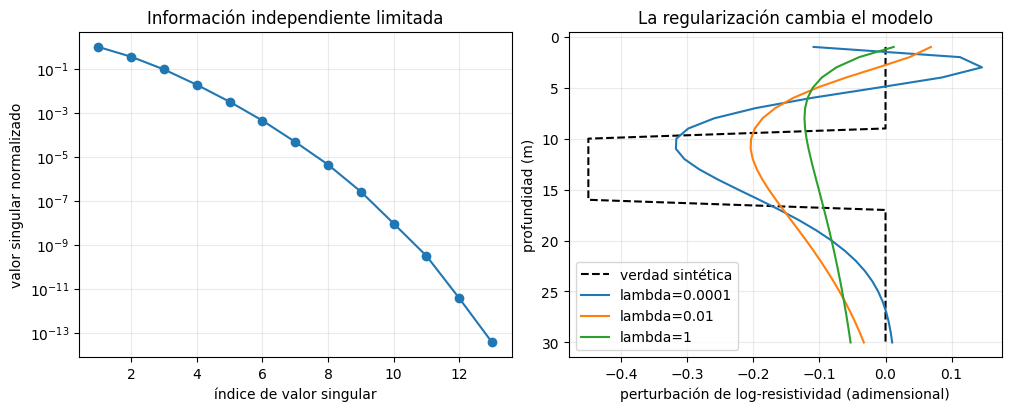

Solo proxy didáctico linealizado; no es resultado de campo ni recibo del solver del producto.


In [3]:
# Execute the documented experiment with the repository evidence.
import numpy as np, matplotlib.pyplot as plt
z=np.linspace(1,30,30); spacing=np.geomspace(2,40,18)
G=np.exp(-z[None,:]/spacing[:,None]); G/=np.linalg.norm(G,axis=1,keepdims=True)
m_true=np.zeros_like(z); m_true[(z>=10)&(z<=16)]=-.45
rng=np.random.default_rng(314159); d=G@m_true+rng.normal(0,.006,len(spacing))
train=np.arange(len(spacing))%4!=0; hold=~train; s=np.linalg.svd(G[train],compute_uv=False)
print("Matriz proxy didáctica",G.shape,"rango",np.linalg.matrix_rank(G[train]),"condición",f"{s[0]/s[-1]:.2e}")
results=[]
for lam in (1e-4,1e-2,1.):
    m=np.linalg.solve(G[train].T@G[train]+lam*np.eye(len(z)),G[train].T@d[train])
    tr=np.sqrt(np.mean((G[train]@m-d[train])**2)); ho=np.sqrt(np.mean((G[hold]@m-d[hold])**2)); err=np.linalg.norm(m-m_true)/np.linalg.norm(m_true)
    results.append((lam,m)); print(f"lambda={lam:g}; RMSE ajuste={tr:.4g}; RMSE retenido={ho:.4g}; error relativo del modelo={err:.3f}")
fig,ax=plt.subplots(1,2,figsize=(10,4),constrained_layout=True); ax[0].semilogy(np.arange(1,len(s)+1),s/s[0],"o-"); ax[0].set(xlabel="índice de valor singular",ylabel="valor singular normalizado",title="Información independiente limitada"); ax[0].grid(alpha=.25)
ax[1].plot(m_true,z,"k--",label="verdad sintética")
for lam,m in results: ax[1].plot(m,z,label=f"lambda={lam:g}")
ax[1].invert_yaxis(); ax[1].set(xlabel="perturbación de log-resistividad (adimensional)",ylabel="profundidad (m)",title="La regularización cambia el modelo"); ax[1].legend(); ax[1].grid(alpha=.25); plt.show()
print("Solo proxy didáctico linealizado; no es resultado de campo ni recibo del solver del producto.")

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)